# ML Practical B1 — Uber Fare Price Prediction

**Aim:** Predict Uber fares using Linear Regression and Random Forest Regression.

Covers preprocessing, missing values, IQR outlier removal, correlation heatmap, both regression models, MAE/MSE/RMSE/R² evaluation, model comparison, and a sample prediction.

Keep the dataset named `uber.csv` in the same folder as this notebook.

## 1. Import libraries

In [14]:
# If required, uncomment: %pip install pandas numpy matplotlib seaborn scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

## 2. Load and explore dataset

In [21]:
df = pd.read_csv("uber.csv")
display(df.head())
print("Shape:", df.shape)
df.info()
display(df.describe())

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


Shape: (200000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


## 3. Data preprocessing

In [22]:
df.drop(columns=["Unnamed: 0", "key"], inplace=True)

cols = ["fare_amount", "pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude", "passenger_count"]
for col in cols:
    df[col] = pd.to_numeric(df[col])

print("Missing values before cleaning:")
display(df.isnull().sum())
df.dropna(subset=cols, inplace=True)

df = df[(df["fare_amount"] > 0) & df["passenger_count"].between(1, 6)]
df = df[
    df["pickup_latitude"].between(-90, 90) &
    df["dropoff_latitude"].between(-90, 90) &
    df["pickup_longitude"].between(-180, 180) &
    df["dropoff_longitude"].between(-180, 180)
].copy()

df = df[
    (df["pickup_latitude"] != 0) & (df["dropoff_latitude"] != 0) &
    (df["pickup_longitude"] != 0) & (df["dropoff_longitude"] != 0)
].copy()

print("Shape after preprocessing:", df.shape)
display(df.isnull().sum())

Missing values before cleaning:


fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Shape after preprocessing: (195313, 7)


fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

## 4. Outlier detection and removal using IQR

Q1: 5.7 Q3: 11.0 IQR: 5.3
Lower bound: -2.249999999999999 Upper bound: 18.95


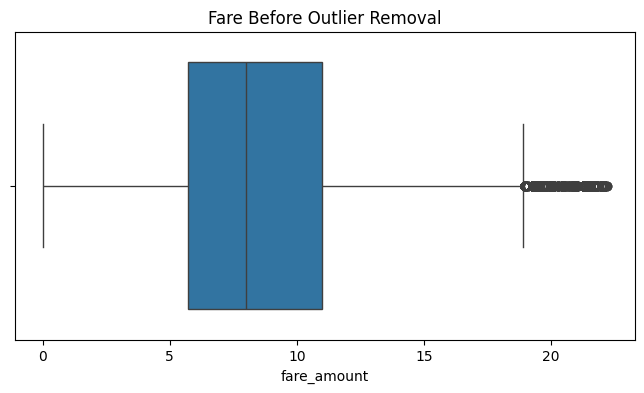

Shape after outlier removal: (172997, 7)


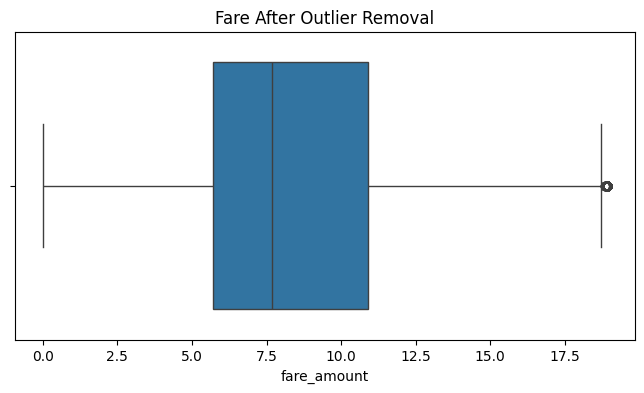

In [26]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1, "Q3:", Q3, "IQR:", IQR)
print("Lower bound:", lower, "Upper bound:", upper)

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Before Outlier Removal")
plt.show()

df = df[df["fare_amount"].between(lower, upper)].copy()
print("Shape after outlier removal:", df.shape)

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare After Outlier Removal")
plt.show()

## 5. Correlation analysis

fare_amount          1.000000
passenger_count      0.015721
dropoff_longitude    0.002265
pickup_longitude     0.001515
pickup_latitude     -0.002634
dropoff_latitude    -0.002934
Name: fare_amount, dtype: float64

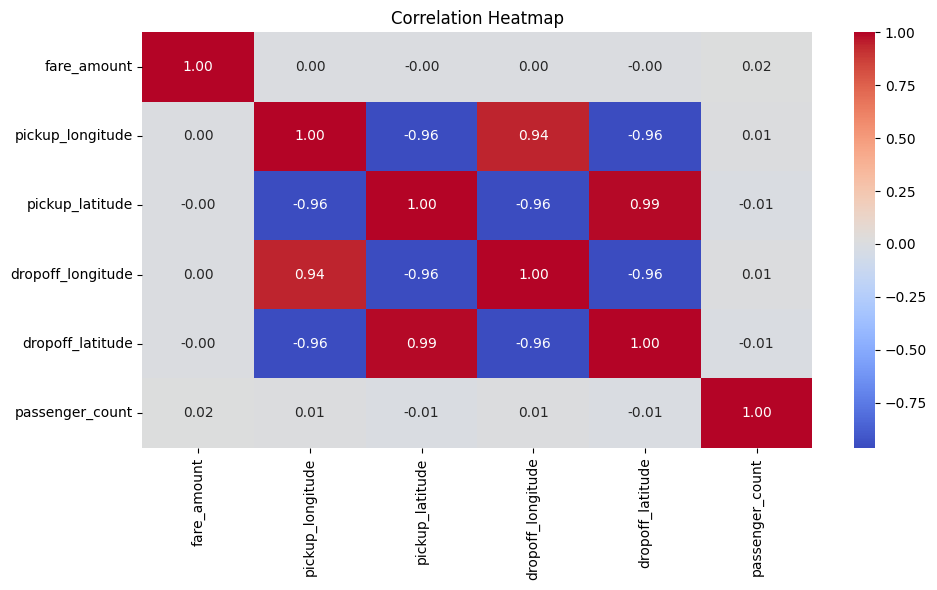

In [29]:
corr = df.select_dtypes(include=np.number).corr()
display(corr["fare_amount"].sort_values(ascending=False))

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 6. Train-test split

In [6]:
X = df[["pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude", "passenger_count"]]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142858, 5)
Testing data: (35715, 5)


## 7. Linear Regression

In [7]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
print("Linear Regression trained successfully.")

Linear Regression trained successfully.


## 8. Random Forest Regression

In [8]:
rf_model = RandomForestRegressor(
    n_estimators=50, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Random Forest Regression trained successfully.")

Random Forest Regression trained successfully.


## 9. Model evaluation and comparison

In [9]:
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    return mae, mse, rmse, r2

lr_mae, lr_mse, lr_rmse, lr_r2 = evaluate_model(y_test, lr_pred)
rf_mae, rf_mse, rf_rmse, rf_r2 = evaluate_model(y_test, rf_pred)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regression"],
    "MAE": [lr_mae, rf_mae],
    "MSE": [lr_mse, rf_mse],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})
display(results.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,3.3182,17.3543,4.1659,0.0002
1,Random Forest Regression,1.5540,4.9132,2.2166,0.7170


## 10. Actual vs predicted visualization

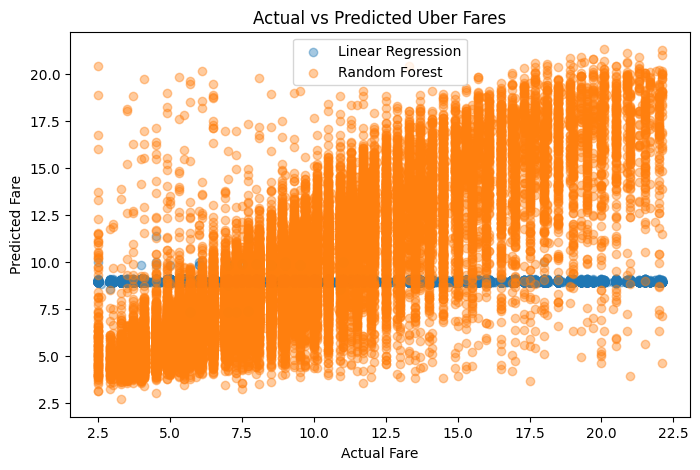

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, lr_pred, alpha=0.4, label="Linear Regression")
plt.scatter(y_test, rf_pred, alpha=0.4, label="Random Forest")
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fares")
plt.legend()
plt.show()

## 11. Final result and conclusion

In [12]:
if rf_rmse < lr_rmse:
    print("Random Forest performs better based on RMSE.")
elif lr_rmse < rf_rmse:
    print("Linear Regression performs better based on RMSE.")
else:
    print("Both models have equal RMSE.")

if rf_r2 > lr_r2:
    print("Random Forest has the higher R2 score.")
elif lr_r2 > rf_r2:
    print("Linear Regression has the higher R2 score.")
else:
    print("Both models have equal R2 scores.")

Random Forest performs better based on RMSE.
Random Forest has the higher R2 score.


### Conclusion
The Uber Fares Dataset was preprocessed by removing unnecessary columns, handling missing values and invalid records. Fare outliers were identified and removed using the IQR method. Correlation analysis was performed using a heatmap. Linear Regression and Random Forest Regression models were trained and evaluated using MAE, MSE, RMSE and R², and their performance was compared.

**Interpretation:** Lower MAE, MSE and RMSE indicate smaller prediction errors. Higher R² indicates better explanatory performance. Record the actual scores produced by your run.

**Note:** This simplified version uses the original pickup/drop-off coordinates and passenger count. It skips Haversine distance calculation and date/time feature extraction while retaining the explicitly listed practical requirements.